In [ ]:
#Install required packages (run once if needed)
%pip install -q librosa soundfile scipy matplotlib pydub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\shash\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


File: Original_Sharpen.wav
Sampling rate: 44100 Hz
Duration: 17.66 seconds
Nyquist frequency: 22050 Hz


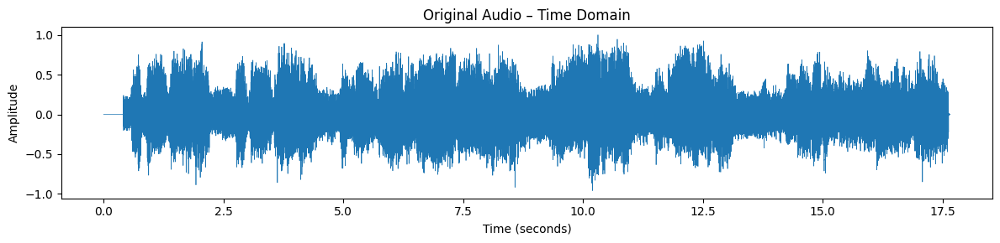

In [16]:
#Importing the librarys and audio-file setup
import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf

from scipy.signal import butter, sosfiltfilt
from IPython.display import Audio, display

# Google Colab: upload your MP3 file when prompted.
# If running in VS Code/Jupyter, set AUDIO_PATH to your local MP3 path.
AUDIO_PATH = "Processed_Audio/Original_Sharpen.wav"

try:
    from google.colab import files
    if not AUDIO_PATH:
        uploaded = files.upload()
        AUDIO_PATH = next(iter(uploaded))
except ImportError:
    if not AUDIO_PATH:
       AUDIO_PATH = r"C:\Users\shash\Downloads\Apsara Aali _ A Carnatic Quartet #acarnaticquartet #apsaraaali.mp3"

if not os.path.isfile(AUDIO_PATH):
    raise FileNotFoundError(
        f"Audio file not found: {AUDIO_PATH}\n"
        "Set AUDIO_PATH to the correct MP3 path and run this cell again."
    )

y, sr = librosa.load(AUDIO_PATH, sr=None, mono=True)
duration = len(y) / sr

print(f"File: {os.path.basename(AUDIO_PATH)}")
print(f"Sampling rate: {sr} Hz")
print(f"Duration: {duration:.2f} seconds")
print(f"Nyquist frequency: {sr/2:.0f} Hz")

plt.figure(figsize=(12, 3))
time = np.arange(len(y)) / sr
plt.plot(time, y, linewidth=0.5)
plt.title("Original Audio – Time Domain")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

display(Audio(y, rate=sr))

Cutoff frequency: 500 Hz
Saved: lowpass_500Hz.wav


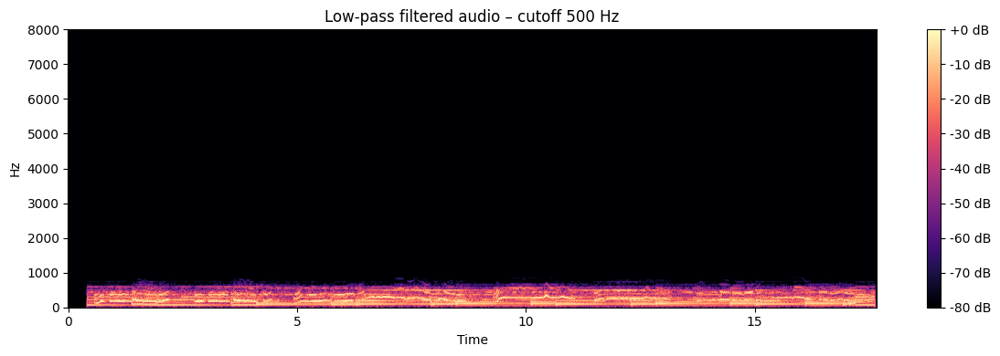

Cutoff frequency: 1500 Hz
Saved: lowpass_1500Hz.wav


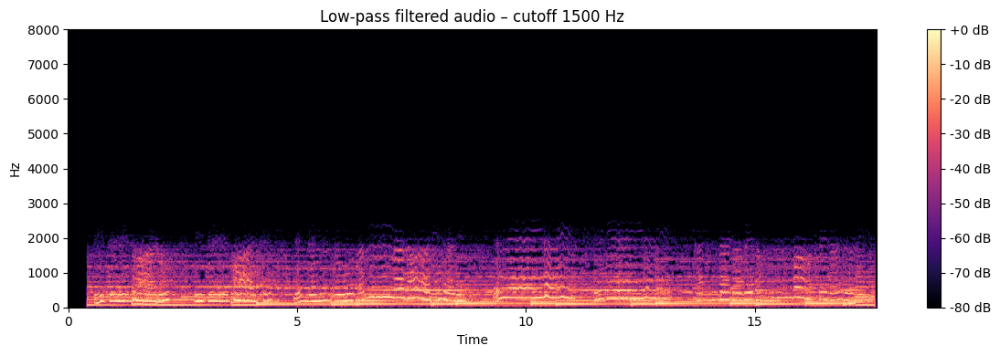

Cutoff frequency: 3000 Hz
Saved: lowpass_3000Hz.wav


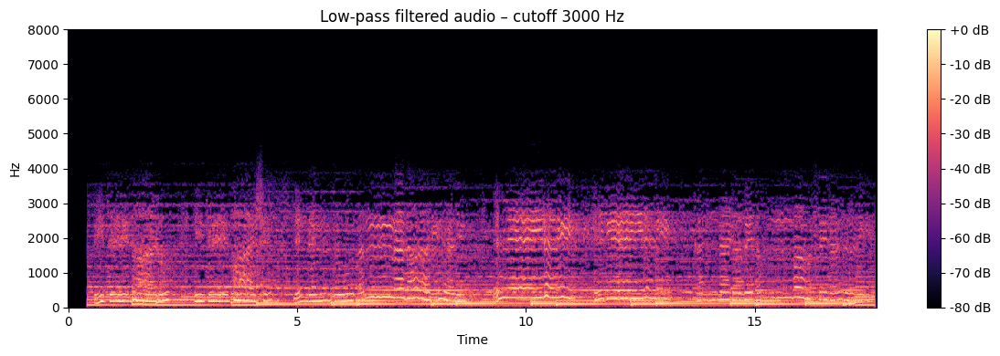

In [ ]:
#The Low-pass filter functions
def butter_lowpass_filter(data, cutoff, fs, order=6):
    if not 0 < cutoff < fs / 2:
        raise ValueError(f"Cutoff must be between 0 and Nyquist ({fs/2:.1f} Hz).")
    sos = butter(order, cutoff, btype="lowpass", fs=fs, output="sos")
    return sosfiltfilt(sos, data)

def plot_spectrogram(signal, fs, title, max_frequency=None):
    n_fft = 2048
    hop = 512
    D = librosa.stft(signal, n_fft=n_fft, hop_length=hop)
    D_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    plt.figure(figsize=(12, 4))
    librosa.display.specshow(
        D_db, sr=fs, hop_length=hop, x_axis="time", y_axis="hz"
    )
    if max_frequency is not None:
        plt.ylim(0, min(max_frequency, fs/2))
    plt.colorbar(format="%+2.0f dB")
    plt.title(title)
    plt.tight_layout()
    plt.show()

cutoff_frequencies = [500, 1500, 3000]
lowpass_results = {}

for cutoff in cutoff_frequencies:
    filtered = butter_lowpass_filter(y, cutoff, sr, order=6)
    lowpass_results[cutoff] = filtered

    output_name = f"lowpass_{cutoff}Hz.wav"
    sf.write(output_name, filtered, sr)

    print(f"Cutoff frequency: {cutoff} Hz")
    print(f"Saved: {output_name}")
    plot_spectrogram(filtered, sr, f"Low-pass filtered audio – cutoff {cutoff} Hz",
                     max_frequency=min(8000, sr/2))
    display(Audio(filtered, rate=sr))

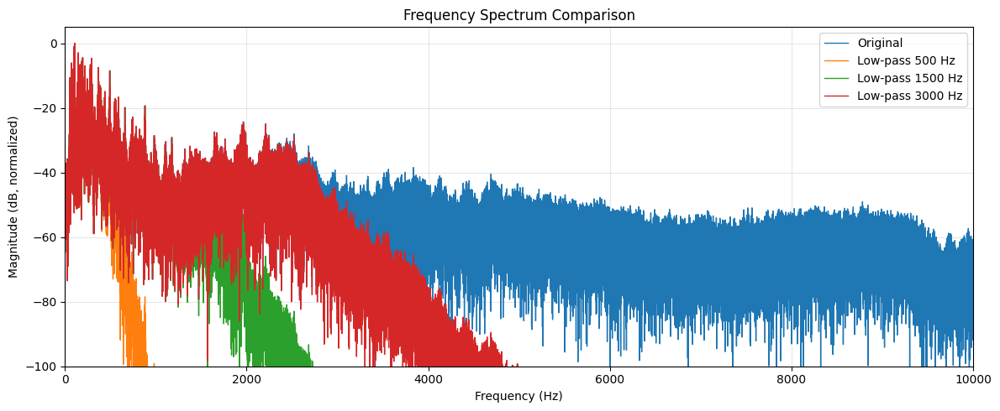

In [17]:
#Comparing the original and filtered signals in the frequency domain
plt.figure(figsize=(12, 5))

def plot_mean_spectrum(signal, fs, label):
    spectrum = np.abs(np.fft.rfft(signal))
    frequencies = np.fft.rfftfreq(len(signal), d=1/fs)
    spectrum_db = 20 * np.log10(spectrum / (np.max(spectrum) + 1e-12) + 1e-12)
    plt.plot(frequencies, spectrum_db, label=label, linewidth=1)

plot_mean_spectrum(y, sr, "Original")
for cutoff, filtered in lowpass_results.items():
    plot_mean_spectrum(filtered, sr, f"Low-pass {cutoff} Hz")

plt.xlim(0, min(10000, sr/2))
plt.ylim(-100, 5)
plt.title("Frequency Spectrum Comparison")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB, normalized)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Spectrum Band-pass filtering
def butter_bandpass_filter(data, lowcut, highcut, fs, order=6):
    if not (0 < lowcut < highcut < fs/2):
        raise ValueError(
            f"Require 0 < lowcut < highcut < Nyquist ({fs/2:.1f} Hz)."
        )
    sos = butter(
        order, [lowcut, highcut], btype="bandpass", fs=fs, output="sos"
    )
    return sosfiltfilt(sos, data)

lowcut = 300
highcut = min(3400, int(sr/2 - 1))

vocal_band = butter_bandpass_filter(y, lowcut, highcut, sr, order=6)
background_estimate = y - vocal_band

print(f"Band-pass range: {lowcut}–{highcut} Hz")
print("Listening to band-pass output (estimated vocal-frequency range):")
display(Audio(vocal_band, rate=sr))

print("Listening to residual (estimated background/out-of-band content):")
display(Audio(background_estimate, rate=sr))

Band-pass range: 300–3400 Hz
Listening to band-pass output (estimated vocal-frequency range):


Listening to residual (estimated background/out-of-band content):


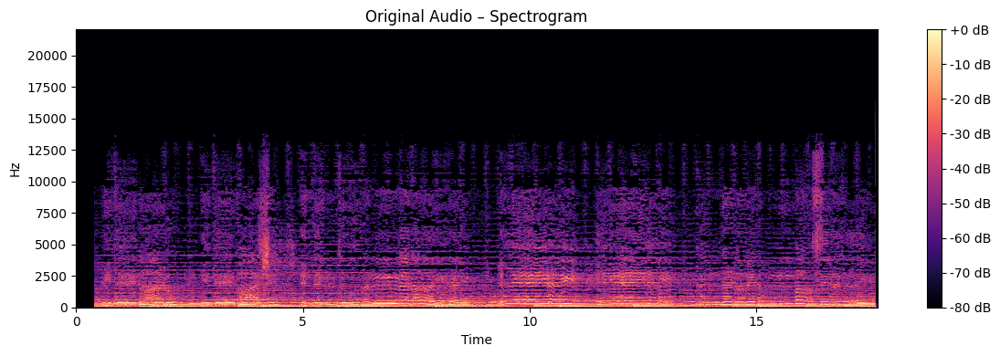

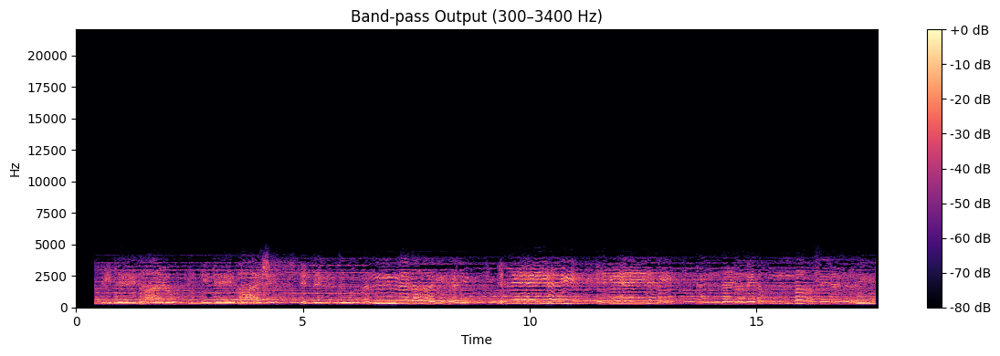

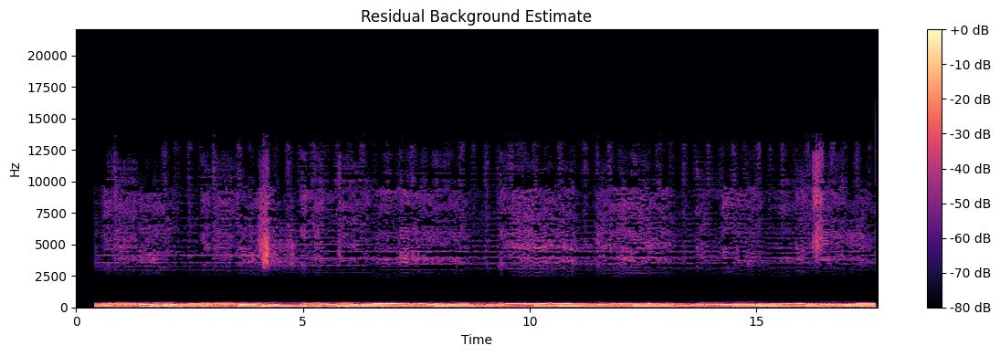

In [18]:
# spectrogram  residual background estimate
plot_spectrogram(y, sr, "Original Audio – Spectrogram")
plot_spectrogram(vocal_band, sr, f"Band-pass Output ({lowcut}–{highcut} Hz)")
plot_spectrogram(background_estimate, sr, "Residual Background Estimate")

In [ ]:
#Saving the  both results as WAV and MP3 files
# WAV files are lossless. MP3 export requires FFmpeg.
import shutil
import subprocess

vocal_wav = "filtered_vocals.wav"
background_wav = "estimated_background.wav"

sf.write(vocal_wav, vocal_band, sr)
sf.write(background_wav, background_estimate, sr)

print(f"Saved {vocal_wav}")
print(f"Saved {background_wav}")

ffmpeg_path = shutil.which("ffmpeg")

if ffmpeg_path:
    subprocess.run(
        [ffmpeg_path, "-y", "-i", vocal_wav, "-b:a", "192k", "filtered_vocals.mp3"],
        check=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE
    )
    subprocess.run(
        [ffmpeg_path, "-y", "-i", background_wav, "-b:a", "192k", "estimated_background.mp3"],
        check=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE
    )
    print("Saved filtered_vocals.mp3")
    print("Saved estimated_background.mp3")
else:
    print("FFmpeg was not found, so MP3 files were not created.")
    print("Install FFmpeg and rerun this cell to export MP3 files.")
    print("WAV outputs have already been saved.")

Saved filtered_vocals.wav
Saved estimated_background.wav
FFmpeg was not found, so MP3 files were not created.
Install FFmpeg and rerun this cell to export MP3 files.
WAV outputs have already been saved.
